In [1]:
from src.baseline.qwen3 import init_model
from pathlib import Path
from typing import List, Dict, Any
import statistics
import json


def read_jsonl_file(path: Path) -> List[Dict[str, Any]]:
    with path.open('r', encoding='utf-8') as f:
        return [json.loads(line) for line in f if line.strip()]


tokenizer, model = init_model("Qwen/Qwen3-0.6B")

d:\GitHub\text2sql_distillation_draft\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 311/311 [00:02<00:00, 104.05it/s]
Some parameters are on the meta device because they were offloaded to the disk and cpu.


In [2]:
benchmark_dir = Path("benchmarks") / "spider_data" / "format_data"

raw_train_data = read_jsonl_file(benchmark_dir / "train.jsonl")
raw_dev_data = read_jsonl_file(benchmark_dir / "dev.jsonl")
raw_test_data = read_jsonl_file(benchmark_dir / "test.jsonl")



In [3]:
def get_prompt_text(tokenizer, system_prompt: str, user_prompt: str, enable_thinking: bool = False) -> str:
    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": user_prompt},
    ]
    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=enable_thinking,
    )
    return text


def token_length(tokenizer, text: str, model_device=None) -> int:
    inputs = tokenizer(text, return_tensors="pt")
    if model_device is not None:
        inputs = inputs.to(model_device)
    return inputs["input_ids"].shape[-1]


def summarize_lengths(lengths: List[int]) -> Dict[str, Any]:
    if not lengths:
        return {}

    lengths_sorted = sorted(lengths)
    n = len(lengths_sorted)

    def percentile(p: float) -> float:
        if n == 1:
            return lengths_sorted[0]
        idx = (n - 1) * p
        low = int(idx)
        high = min(low + 1, n - 1)
        frac = idx - low
        return lengths_sorted[low] * (1 - frac) + lengths_sorted[high] * frac

    return {
        "count": n,
        "min": min(lengths_sorted),
        "max": max(lengths_sorted),
        "mean": sum(lengths_sorted) / n,
        "median": statistics.median(lengths_sorted),
        "p50": percentile(0.50),
        "p90": percentile(0.90),
        "p95": percentile(0.95),
        "p99": percentile(0.99),
    }



In [4]:
from tqdm.auto import tqdm


def analyze_dataset_token_lengths(
    dataset: List[Dict[str, Any]],
    tokenizer,
    enable_thinking: bool = False,
):
    prompt_lengths = []
    prompt_plus_response_lengths = []
    response_only_lengths = []

    results = []

    for i, item in tqdm(enumerate(dataset), total=len(dataset)):
        prompt_text = get_prompt_text(
            tokenizer=tokenizer,
            system_prompt=item["system_prompt"],
            user_prompt=item["user_prompt"],
            enable_thinking=enable_thinking,
        )
        response_text = item["response"]

        prompt_len = token_length(tokenizer, prompt_text)
        full_text = prompt_text + response_text
        full_len = token_length(tokenizer, full_text)
        response_len = full_len - prompt_len

        prompt_lengths.append(prompt_len)
        prompt_plus_response_lengths.append(full_len)
        response_only_lengths.append(response_len)

        results.append({
            "idx": i,
            "prompt_len": prompt_len,
            "prompt_plus_response_len": full_len,
            "response_len_only": response_len,
        })

    summary = {
        "prompt_only": summarize_lengths(prompt_lengths),
        "response_only": summarize_lengths(response_only_lengths),
        "prompt_plus_response": summarize_lengths(prompt_plus_response_lengths),
    }

    return results, summary



In [13]:
results, summary = analyze_dataset_token_lengths(raw_test_data, tokenizer, enable_thinking=False)
# results, summary = analyze_dataset_token_lengths(raw_dev_data, tokenizer, enable_thinking=False)
# results, summary = analyze_dataset_token_lengths(raw_train_data, tokenizer, enable_thinking=False)



100%|██████████| 2147/2147 [00:10<00:00, 210.79it/s]


In [14]:
summary


{'prompt_only': {'count': 2147,
  'min': 276,
  'max': 709,
  'mean': 385.09455053563113,
  'median': 348,
  'p50': 348.0,
  'p90': 517.0,
  'p95': 676.0,
  'p99': 692.54},
 'response_only': {'count': 2147,
  'min': 9,
  'max': 151,
  'mean': 36.66977177456916,
  'median': 27,
  'p50': 27.0,
  'p90': 67.0,
  'p95': 82.0,
  'p99': 126.0},
 'prompt_plus_response': {'count': 2147,
  'min': 285,
  'max': 856,
  'mean': 421.76432231020027,
  'median': 383,
  'p50': 383.0,
  'p90': 571.0,
  'p95': 705.6999999999998,
  'p99': 753.0}}

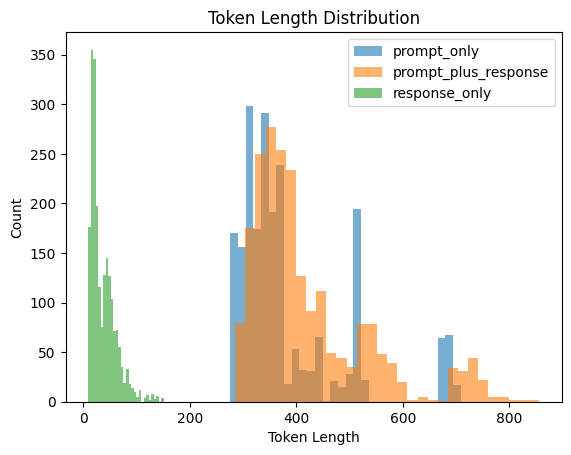

In [15]:
import matplotlib.pyplot as plt

prompt_lens = [x["prompt_len"] for x in results]
full_lens = [x["prompt_plus_response_len"] for x in results]
response_lens = [x["response_len_only"] for x in results]

plt.figure()
plt.hist(prompt_lens, bins=30, alpha=0.6, label="prompt_only")
plt.hist(full_lens, bins=30, alpha=0.6, label="prompt_plus_response")
plt.hist(response_lens, bins=30, alpha=0.6, label="response_only")

plt.xlabel("Token Length")
plt.ylabel("Count")
plt.title("Token Length Distribution")
plt.legend()

plt.show()



In [16]:
sorted(results, key=lambda x: x["prompt_plus_response_len"], reverse=True)[:10]


[{'idx': 461,
  'prompt_len': 705,
  'prompt_plus_response_len': 856,
  'response_len_only': 151},
 {'idx': 462,
  'prompt_len': 704,
  'prompt_plus_response_len': 855,
  'response_len_only': 151},
 {'idx': 463,
  'prompt_len': 697,
  'prompt_plus_response_len': 835,
  'response_len_only': 138},
 {'idx': 464,
  'prompt_len': 693,
  'prompt_plus_response_len': 826,
  'response_len_only': 133},
 {'idx': 441,
  'prompt_len': 702,
  'prompt_plus_response_len': 805,
  'response_len_only': 103},
 {'idx': 442,
  'prompt_len': 700,
  'prompt_plus_response_len': 803,
  'response_len_only': 103},
 {'idx': 1469,
  'prompt_len': 685,
  'prompt_plus_response_len': 793,
  'response_len_only': 108},
 {'idx': 1468,
  'prompt_len': 682,
  'prompt_plus_response_len': 790,
  'response_len_only': 108},
 {'idx': 444,
  'prompt_len': 709,
  'prompt_plus_response_len': 788,
  'response_len_only': 79},
 {'idx': 443,
  'prompt_len': 704,
  'prompt_plus_response_len': 783,
  'response_len_only': 79}]